In [ ]:
# Import the datasets
import pandas as pd
demo = pd.read_sas("/content/DEMO_L.xpt")
bmx  = pd.read_sas("/content/BMX_L.xpt")
bp   = pd.read_sas("/content/BPXO_L.xpt")
chol = pd.read_sas("/content/TCHOL_L.xpt")
smok = pd.read_sas("/content/SMQ_L.xpt")
mcq  = pd.read_sas("/content/MCQ_L.xpt")
bpq  = pd.read_sas("/content/BPQ_L.xpt")
diq  = pd.read_sas("/content/DIQ_L.xpt")


# Merge the datasets
df = demo.merge(bmx, on="SEQN", how="inner") \
         .merge(bp, on="SEQN", how="inner") \
         .merge(chol, on="SEQN", how="inner") \
         .merge(mcq, on="SEQN", how="inner") \
         .merge(smok, on="SEQN", how="inner")\
         .merge(bpq, on="SEQN", how="inner")\
         .merge(diq, on="SEQN", how="inner")
print(df.shape)
df.head()


(6615, 117)


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,BPQ080,BPQ101D,DIQ010,DID040,DIQ160,DIQ180,DIQ050,DID060,DIQ060U,DIQ070
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,2.0,2.0,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,2.0,2.0,2.0,NaN,2.0,1.0,NaN,NaN,NaN,NaN
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,1.0,1.0,1.0,35.0,NaN,NaN,2.0,NaN,NaN,1.0
3,130386.0,12.0,2.0,1.0,34.0,NaN,1.0,1.0,1.0,NaN,...,2.0,2.0,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN
4,130387.0,12.0,2.0,2.0,68.0,NaN,3.0,3.0,2.0,NaN,...,1.0,2.0,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN


## Data Preperation

### Whole dataset preparation

In [ ]:
# Output total variables in dataset
print("Total variables:", len(df.columns))
print("\nVariable list:")
for col in df.columns:
    print(col)


Total variables: 117

Variable list:
SEQN
SDDSRVYR
RIDSTATR
RIAGENDR
RIDAGEYR
RIDAGEMN
RIDRETH1
RIDRETH3
RIDEXMON
RIDEXAGM
DMQMILIZ
DMDBORN4
DMDYRUSR
DMDEDUC2
DMDMARTZ
RIDEXPRG
DMDHHSIZ
DMDHRGND
DMDHRAGZ
DMDHREDZ
DMDHRMAZ
DMDHSEDZ
WTINT2YR
WTMEC2YR
SDMVSTRA
SDMVPSU
INDFMPIR
BMDSTATS
BMXWT
BMIWT
BMXRECUM
BMIRECUM
BMXHEAD
BMIHEAD
BMXHT
BMIHT
BMXBMI
BMDBMIC
BMXLEG
BMILEG
BMXARML
BMIARML
BMXARMC
BMIARMC
BMXWAIST
BMIWAIST
BMXHIP
BMIHIP
BPAOARM
BPAOCSZ
BPXOSY1
BPXODI1
BPXOSY2
BPXODI2
BPXOSY3
BPXODI3
BPXOPLS1
BPXOPLS2
BPXOPLS3
WTPH2YR
LBXTC
LBDTCSI
MCQ010
MCQ035
MCQ040
MCQ050
AGQ030
MCQ053
MCQ149
MCQ160A
MCQ195
MCQ160B
MCQ160C
MCQ160D
MCQ160E
MCQ160F
MCQ160M
MCQ170M
MCQ160P
MCQ160L
MCQ170L
MCQ500
MCQ510A
MCQ510B
MCQ510C
MCQ510D
MCQ510E
MCQ510F
MCQ550
MCQ560
MCQ220
MCQ230A
MCQ230B
MCQ230C
MCQ230D
OSQ230
SMQ020
SMQ040
SMD641
SMD650
SMD100MN
SMQ621
SMD630
SMAQUEX2
BPQ020
BPQ030
BPQ150
BPQ080
BPQ101D
DIQ010
DID040
DIQ160
DIQ180
DIQ050
DID060
DIQ060U
DIQ070


In [ ]:
# Create missingness summary of all variables in dataset
summary = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": df.isna().mean() * 100
})

summary = summary.sort_values("pct_missing", ascending=False)

summary.head(20)
high_missing = summary[summary["pct_missing"] > 50]
high_missing.sort_values("pct_missing", ascending=False)


,n_missing,pct_missing
RIDAGEMN,6615,100.000000
BMXRECUM,6615,100.000000
BMIRECUM,6615,100.000000
BMXHEAD,6615,100.000000
BMIHEAD,6615,100.000000
MCQ149,6615,100.000000
MCQ230D,6613,99.969766
MCQ510B,6611,99.939531
MCQ510E,6603,99.818594
SMD630,6600,99.773243


In [ ]:
# Determine the output for blood pressure medication use
df["BPQ080"].value_counts(dropna=False)
# 1 means yes, 2 means no and 9 means don't know, and there is no missing values

,count
BPQ080,
2.0,4041
1.0,2538
9.0,36


In [ ]:
# Determine the output for diabetes use
df["DIQ010"].value_counts(dropna=False).sort_index()
# 1 = Yes, diagnosed diabetes, 2 = No diagnosed diabetes, 3 = Borderline diabetes, 9 = Don't know

,count
DIQ010,
1.0,871
2.0,5520
3.0,223
9.0,1


In [ ]:
# Create corrected diabetes indicator
df["diabetes"] = df["DIQ010"].map({
    1: 1,  # Diagnosed diabetes
    2: 0   # No diagnosed diabetes
})
# Borderline (3), refused (7), don't know (9) and missing responses become NaN

# Check classification
print(df["diabetes"].value_counts(dropna=False))

diabetes
0.0    5520
1.0     871
NaN     224
Name: count, dtype: int64


In [ ]:
# Turns output of blood pressure medication to 0/1 (no BP medication/ on BP medication)
df["HTN_med"] = df["BPQ080"].replace({1:1, 2:0})
df = df[df["HTN_med"].isin([0,1])]

In [ ]:
# Determine the output for diagnosed Hyptertension
df["BPQ020"].value_counts(dropna=False)
# 1 means yes, 2 means no and 9 means don't know

,count
BPQ020,
2.0,4263
1.0,2312
9.0,4


In [ ]:
# Turn output of diagnosed hypertension to 0/1 (no diagnosis/ doctor diagnosed hypertension)
df["HTN_diagnosed"] = df["BPQ020"].replace({1:1, 2:0})
df = df[df["HTN_diagnosed"].isin([0,1])]

In [ ]:
# Compute the average for Systolic and Diastolic Blood Pressure among the 3 trials
df["SBP_avg"] = df[["BPXOSY1","BPXOSY2","BPXOSY3"]].mean(axis=1)
df["DBP_avg"] = df[["BPXODI1","BPXODI2","BPXODI3"]].mean(axis=1)
# first trial can be high for people nervous about the procedure so an average is preferred among 3 trials

In [ ]:
# Create a threshold upon guidelines where these measuremnts have often marked Hypertension
df["HTN_clinical"] = (
    (df["SBP_avg"] >= 130) |
    (df["DBP_avg"] >= 80) |
    (df["HTN_med"] == 1)
).astype(int)

In [ ]:
# Determine the output for Coronary heart disease
df["MCQ160B"].value_counts(dropna=False)

,count
MCQ160B,
2.0,5760
NaN,550
1.0,256
9.0,9


In [ ]:
# Determine the output for Angina
df["MCQ160C"].value_counts(dropna=False)

,count
MCQ160C,
2.0,5678
NaN,551
1.0,322
9.0,24


In [ ]:
# Determine the output for Heart attack
df["MCQ160E"].value_counts(dropna=False)

,count
MCQ160E,
2.0,5756
NaN,551
1.0,259
9.0,9


In [ ]:
# Determine the output for Stroke
df["MCQ160F"].value_counts(dropna=False)

,count
MCQ160F,
2.0,5735
NaN,552
1.0,279
9.0,9


In [ ]:
import numpy as np
cvd_vars = ["MCQ160B", "MCQ160C", "MCQ160E", "MCQ160F"]

# Recode yes/no responses only
for col in cvd_vars:
    df[col] = df[col].replace({
        1: 1,   # Yes
        2: 0,   # No
        9: np.nan  # Don't know -> missing
    })

# Drop rows with missing on any of the CVD-defining conditions
df = df.dropna(subset=cvd_vars).copy()

# Create composite CVD outcome
df["CVD"] = df[cvd_vars].max(axis=1).astype(int)

In [ ]:
df["CVD"] = (
    (df["MCQ160B"] == 1) |
    (df["MCQ160C"] == 1) |
    (df["MCQ160E"] == 1) |
    (df["MCQ160F"] == 1)
).astype(int)

In [ ]:
cvd_vars = ["MCQ160B", "MCQ160C", "MCQ160E", "MCQ160F"]

print("=== RESPONSE CODE DISTRIBUTIONS ===")

for var in cvd_vars:
    print(f"\n{var}:")
    print(df[var].value_counts(dropna=False).sort_index())

print("\n=== MISSING COUNTS ===")
print(df[cvd_vars].isna().sum())

print("\n=== MISSING PERCENTAGES ===")
print((df[cvd_vars].isna().mean() * 100).round(2))

print("\n=== COMPLETE VS INCOMPLETE CVD RESPONSES ===")
print("All 4 responses available:",
      df[cvd_vars].notna().all(axis=1).sum())

print("At least 1 response missing:",
      (~df[cvd_vars].notna().all(axis=1)).sum())

print("All 4 responses missing:",
      df[cvd_vars].isna().all(axis=1).sum())

=== RESPONSE CODE DISTRIBUTIONS ===

MCQ160B:
MCQ160B
0.0    5732
1.0     244
Name: count, dtype: int64

MCQ160C:
MCQ160C
0.0    5661
1.0     315
Name: count, dtype: int64

MCQ160E:
MCQ160E
0.0    5732
1.0     244
Name: count, dtype: int64

MCQ160F:
MCQ160F
0.0    5705
1.0     271
Name: count, dtype: int64

=== MISSING COUNTS ===
MCQ160B    0
MCQ160C    0
MCQ160E    0
MCQ160F    0
dtype: int64

=== MISSING PERCENTAGES ===
MCQ160B    0.0
MCQ160C    0.0
MCQ160E    0.0
MCQ160F    0.0
dtype: float64

=== COMPLETE VS INCOMPLETE CVD RESPONSES ===
All 4 responses available: 5976
At least 1 response missing: 0
All 4 responses missing: 0


### Hypertension data preparation

In [ ]:
# Variables for Hypertension for Further Testing
keep_cols_htn = [
    # demographics / background
    "RIDAGEYR", "RIAGENDR", "RIDRETH3", # patient age, sex, and ethnicity
    "INDFMPIR", # patient income to poverty ratio

    # metabolic
    "BMXBMI", # body mass index
    "LBXTC", # total cholesterol

    # behavior
    "SMQ020", # smoking history (100+ cigarettes lifetime)

    # comorbidity
    "diabetes",  # diabetes diagnosis (replaces MCQ010)

    # outcome
    "HTN_clinical"
]

# Create hypertension analysis dataset
df_htn = df[keep_cols_htn].copy()

# Confirm variables and dataset dimensions
print("Dataset shape:", df_htn.shape)
print("\nVariables:")
print(df_htn.columns.tolist())

Dataset shape: (5976, 9)

Variables:
['RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'INDFMPIR', 'BMXBMI', 'LBXTC', 'SMQ020', 'diabetes', 'HTN_clinical']


In [ ]:
# Missingness check for kept columns
df_htn.isna().mean().sort_values(ascending=False)

,0
INDFMPIR,0.129183
LBXTC,0.092704
diabetes,0.035977
BMXBMI,0.015228
RIDAGEYR,0.000000
RIAGENDR,0.000000
RIDRETH3,0.000000
SMQ020,0.000000
HTN_clinical,0.000000


In [ ]:
# Convert values to binary (0-male/1-female)
# Sex: 1=Male, 2=Female  -> 0/1
df_htn["RIAGENDR"] = df_htn["RIAGENDR"].map({1: 0, 2: 1})

# Smoking: 1=Yes, 2=No -> 1/0
df_htn["SMQ020"] = df_htn["SMQ020"].replace({2: 0})

In [ ]:
# Filter to valid binary codes
df_htn_clean = df_htn[
    df_htn["SMQ020"].isin([0, 1]) &
    df_htn["diabetes"].isin([0, 1])
].copy()

# Variables required for the HTN analysis
core_vars_htn = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH3", "INDFMPIR",
    "BMXBMI", "LBXTC", "SMQ020", "diabetes",
    "HTN_clinical"
]

# Keep required variables and remove missing observations
df_htn_clean = df_htn_clean[core_vars_htn].dropna().copy()

print("Original N (df_htn):", len(df_htn))
print("Clean N (df_htn_clean):", len(df_htn_clean))

Original N (df_htn): 5976
Clean N (df_htn_clean): 4499


In [ ]:
# Find the HTN prevalance in the Data
print("Clinical HTN prevalence:", df_htn_clean["HTN_clinical"].mean())
print("Diabetes prevalence:", df_htn_clean["diabetes"].mean())
print("Smoker prevalence:", df_htn_clean["SMQ020"].mean())

Clinical HTN prevalence: 0.6234718826405868
Diabetes prevalence: 0.1411424761058013
Smoker prevalence: 0.4123138475216715


### CVD data preperation

In [ ]:
keep_cols_cvd = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH3", "INDFMPIR",
    "BMXBMI", "LBXTC",
    "SMQ020",
    "diabetes",
    "HTN_clinical",
    "CVD"
]
df_cvd = df[keep_cols_cvd].copy()

In [ ]:
# Missingness check for kept columns
df_cvd.isna().mean().sort_values(ascending=False)

,0
INDFMPIR,0.129183
LBXTC,0.092704
diabetes,0.035977
BMXBMI,0.015228
RIAGENDR,0.000000
RIDAGEYR,0.000000
RIDRETH3,0.000000
SMQ020,0.000000
HTN_clinical,0.000000
CVD,0.000000


In [ ]:
# Convert values to binary (0-male/1-female)
# Sex: 1=Male, 2=Female  -> 0/1
df_cvd["RIAGENDR"] = df_cvd["RIAGENDR"].map({1: 0, 2: 1})

# Smoking: 1=Yes, 2=No -> 1/0
df_cvd["SMQ020"] = df_cvd["SMQ020"].replace({2: 0})


In [ ]:
# Filter to valid binary codes
df_cvd_clean = df_cvd[
    df_cvd["SMQ020"].isin([0, 1]) &
    df_cvd["diabetes"].isin([0, 1])
].copy()

In [ ]:
# Filter to valid binary codes
df_cvd_clean = df_cvd[
    df_cvd["SMQ020"].isin([0, 1]) &
    df_cvd["diabetes"].isin([0, 1])
].copy()

# Variables required for the CVD analysis
core_vars_cvd = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH3", "INDFMPIR",
    "BMXBMI", "LBXTC", "SMQ020", "diabetes",
    "HTN_clinical", "CVD"
]

# Keep required variables and remove missing observations
df_cvd_clean = df_cvd_clean[core_vars_cvd].dropna().copy()

print("Original N (df_cvd):", len(df_cvd))
print("Clean N (df_cvd_clean):", len(df_cvd_clean))

Original N (df_cvd): 5976
Clean N (df_cvd_clean): 4499


In [ ]:
print("CVD prevalence:", df_cvd_clean["CVD"].mean())
print("HTN prevalence (in CVD dataset):", df_cvd_clean["HTN_clinical"].mean())
print("Diabetes prevalence:", df_cvd_clean["diabetes"].mean())
print("Smoker prevalence:", df_cvd_clean["SMQ020"].mean())

CVD prevalence: 0.11202489442098244
HTN prevalence (in CVD dataset): 0.6234718826405868
Diabetes prevalence: 0.1411424761058013
Smoker prevalence: 0.4123138475216715


### Dataset Trends

In [ ]:
# count the number of males and females in the dataset
df_htn_clean["RIAGENDR"].value_counts()
df_htn_clean["RIAGENDR"].map({0: "Male", 1: "Female"}).value_counts()

,count
RIAGENDR,
Female,2494
Male,2005


In [ ]:
# Counts with labels
df_htn_clean["RIAGENDR"].map({0: "Male", 1: "Female"}).value_counts()

# Percentages with labels
df_htn_clean["RIAGENDR"].map({0: "Male", 1: "Female"}).value_counts(normalize=True) * 100

,proportion
RIAGENDR,
Female,55.434541
Male,44.565459


In [ ]:
# calculate the average hypertension rate for each gender group
df_htn_clean.groupby("RIAGENDR")["HTN_clinical"].mean()

# Convert numeric gender to text gender
df_htn_clean["gender_label"] = df_htn_clean["RIAGENDR"].map({
    0: "Male",
    1: "Female"
})

df_htn_clean.groupby("gender_label")["HTN_clinical"].mean()

,HTN_clinical
gender_label,
Female,0.585405
Male,0.670823


In [ ]:
# calculate the average hypertension rate for each race in numeric form
df_htn_clean.groupby("RIDRETH3")["HTN_clinical"].mean().sort_values(ascending=False)

# convert numeric gender to text gender labels
race_map = {
    1: "Mexican American",
    2: "Other Hispanic",
    3: "Non-Hispanic White",
    4: "Non-Hispanic Black",
    6: "Non-Hispanic Asian",
    7: "Other/Multi"
}

df_htn_clean["race_label"] = df_htn_clean["RIDRETH3"].map(race_map)

df_htn_clean.groupby("race_label")["HTN_clinical"].mean().sort_values(ascending=False)

,HTN_clinical
race_label,
Non-Hispanic White,0.645068
Non-Hispanic Black,0.639752
Other/Multi,0.623239
Other Hispanic,0.571759
Non-Hispanic Asian,0.562771
Mexican American,0.515464


In [ ]:
# Count the number of occurrences of each race in the dataset
df_htn_clean.groupby(["RIDRETH3","race_label"]).size()

,,0
RIDRETH3,race_label,
1.0,Mexican American,291
2.0,Other Hispanic,432
3.0,Non-Hispanic White,2778
4.0,Non-Hispanic Black,483
6.0,Non-Hispanic Asian,231
7.0,Other/Multi,284


In [ ]:
# keeps only one row per unique race category
df_htn_clean[["RIDRETH3", "race_label"]].drop_duplicates().sort_values("RIDRETH3")

,RIDRETH3,race_label
3,1.0,Mexican American
2,2.0,Other Hispanic
1,3.0,Non-Hispanic White
23,4.0,Non-Hispanic Black
0,6.0,Non-Hispanic Asian
57,7.0,Other/Multi


## Basic Exploratory Data Analysis (EDA)

### Relationship between Clinical Hypertension and predictor variables

In [ ]:
# Relationship between Diabetes and Clinical Hypertension
df_htn_clean.groupby("diabetes")["HTN_clinical"].mean()

,HTN_clinical
diabetes,
0.0,0.583075
1.0,0.869291


In [ ]:
# Relationship between Smoking and Clinical Hypertension
df_htn_clean.groupby("SMQ020")["HTN_clinical"].mean()

,HTN_clinical
SMQ020,
0.0,0.573374
1.0,0.694879


In [ ]:
# Relationship between Age, BMI and Cholesterol with Clinical Hypertension
df_htn_clean.groupby("HTN_clinical")[["RIDAGEYR", "BMXBMI", "LBXTC"]].mean()

,RIDAGEYR,BMXBMI,LBXTC
HTN_clinical,,,
0,44.933884,28.272491,183.253247
1,58.767558,30.668841,191.858467


In [ ]:
# Relationship between Race and Clinical Hypertension
ethnicity_map = {
    1: "Mexican American",
    2: "Other Hispanic",
    3: "White",
    4: "Black",
    6: "Asian"
}

df_htn_clean["ethnicity"] = df_htn_clean["RIDRETH3"].map(ethnicity_map)

df_htn_clean.groupby("ethnicity")["HTN_clinical"].mean()

,HTN_clinical
ethnicity,
Asian,0.562771
Black,0.639752
Mexican American,0.515464
Other Hispanic,0.571759
White,0.645068


In [ ]:
# Relationship between Income and Clinical Hypertension
df_htn_clean["income_group"] = pd.cut(
    df_htn_clean["INDFMPIR"],
    bins=[0, 1, 3, 5],
    labels=["Low", "Middle", "High"]
)

df_htn_clean.groupby("income_group")["HTN_clinical"].mean()

/tmp/ipykernel_7375/646349228.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_htn_clean.groupby("income_group")["HTN_clinical"].mean()


,HTN_clinical
income_group,
Low,0.582822
Middle,0.625230
High,0.634146


In [ ]:
# Summary Stats for Age, BMI, Income and Cholesterol
df_htn_clean[["RIDAGEYR","BMXBMI","INDFMPIR","LBXTC"]].describe()

,RIDAGEYR,BMXBMI,INDFMPIR,LBXTC
count,4499.000000,4499.000000,4.499000e+03,4499.000000
mean,53.558791,29.766548,3.001640e+00,188.618360
std,16.898023,7.240781,1.647423e+00,42.459385
min,20.000000,14.100000,5.397605e-79,62.000000
25%,39.000000,24.700000,1.510000e+00,159.000000
50%,57.000000,28.400000,2.940000e+00,186.000000
75%,67.000000,33.500000,5.000000e+00,214.000000
max,80.000000,74.800000,5.000000e+00,438.000000


Average age of 53 indicates an older population contributing to the higher prevalence values above

Average to poverty is almost 3 indicating middle income range

Average BMI of 29.8 in the dataset which is above the average which ranges from 18 - 25

cholesterol is rougly 188 indicating this dataset's patients fall right at the national average for adults


### Relationship between CVD and all predictor variables

In [ ]:
# Relationship Between Clinical Hypertension and CVD
df_cvd_clean.groupby("HTN_clinical")["CVD"].mean()

,CVD
HTN_clinical,
0,0.040142
1,0.155437


In [ ]:
# Relationship Between diabetes and CVD
df_cvd_clean = df_cvd_clean[df_cvd_clean["diabetes"].isin([0,1])].copy()
df_cvd_clean.groupby("diabetes")["CVD"].mean()

,CVD
diabetes,
0.0,0.083075
1.0,0.288189


In [ ]:
# Relationship Bteween Smoking and CVD
df_cvd_clean = df_cvd_clean[df_cvd_clean["SMQ020"].isin([0,1])].copy()
df_cvd_clean.groupby("SMQ020")["CVD"].mean()

,CVD
SMQ020,
0.0,0.067700
1.0,0.175202


In [ ]:
# Relationship between Age, BMI and Cholesterol with CVD
df_cvd_clean.groupby("CVD")[["RIDAGEYR", "BMXBMI", "LBXTC"]].mean()

,RIDAGEYR,BMXBMI,LBXTC
CVD,,,
0,51.823279,29.591715,191.386483
1,67.315476,31.152381,166.676587


In [ ]:
# Relationship between Race and CVD
ethnicity_map = {
    1: "Mexican American",
    2: "Other Hispanic",
    3: "White",
    4: "Black",
    6: "Asian"
}

df_cvd_clean["ethnicity"] = df_cvd_clean["RIDRETH3"].map(ethnicity_map)

df_cvd_clean.groupby("ethnicity")["CVD"].mean()

,CVD
ethnicity,
Asian,0.077922
Black,0.130435
Mexican American,0.054983
Other Hispanic,0.099537
White,0.117711


In [ ]:
# Relationship between Income and CVD
df_cvd_clean["income_group"] = pd.cut(
    df_cvd_clean["INDFMPIR"],
    bins=[0, 1, 3, 5],
    labels=["Low", "Middle", "High"]
)
df_cvd_clean.groupby("income_group")["CVD"].mean()

/tmp/ipykernel_7375/2070383020.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_cvd_clean.groupby("income_group")["CVD"].mean()


,CVD
income_group,
Low,0.136503
Middle,0.139008
High,0.084914


In [ ]:
# Summary Stats for Age, BMI, Income and Cholesterol
df_cvd_clean[["RIDAGEYR", "BMXBMI", "INDFMPIR", "LBXTC"]].describe()

,RIDAGEYR,BMXBMI,INDFMPIR,LBXTC
count,4499.000000,4499.000000,4.499000e+03,4499.000000
mean,53.558791,29.766548,3.001640e+00,188.618360
std,16.898023,7.240781,1.647423e+00,42.459385
min,20.000000,14.100000,5.397605e-79,62.000000
25%,39.000000,24.700000,1.510000e+00,159.000000
50%,57.000000,28.400000,2.940000e+00,186.000000
75%,67.000000,33.500000,5.000000e+00,214.000000
max,80.000000,74.800000,5.000000e+00,438.000000


## Hypertension Prediction Modeling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

from xgboost import XGBClassifier
import numpy as np

# Outcome + predictors
# Outcome variable
y = df_htn_clean["HTN_clinical"].astype(int)

# Select only the eight predictors for hypertension
predictor_cols = [
    "RIDAGEYR",
    "RIAGENDR",
    "RIDRETH3",
    "INDFMPIR",
    "BMXBMI",
    "LBXTC",
    "SMQ020",
    "diabetes"
]

X = df_htn_clean[predictor_cols].copy()

# Check data types and values
print(X.dtypes)
print("\nSex distribution:")
print(X["RIAGENDR"].value_counts(dropna=False))

# Categorical vs numeric + preprocessing
cat_cols = ["RIDRETH3"]
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
    ]
)
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
# Logistic Regression
log_model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=4000))
])

log_model.fit(X_train, y_train)
auc_log = roc_auc_score(y_test, log_model.predict_proba(X_test)[:, 1])

from sklearn.metrics import classification_report, confusion_matrix

y_pred_log = (log_model.predict_proba(X_test)[:,1] >= 0.5).astype(int)

print("\n=== Logistic Regression Performance ===")
print(confusion_matrix(y_test, y_pred_log))
print(classification_report(y_test, y_pred_log))

# Random forest
rf_model = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=400,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
auc_rf = roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1])

# XGboosting
xgb_model = Pipeline([
    ("prep", preprocess),
    ("clf", XGBClassifier(
        n_estimators=500,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)
auc_xgb = roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1])

print("\n=== HTN_clinical MODEL COMPARISON (df_htn_clean) ===")
print(f"Logistic AUC: {auc_log:.3f}")
print(f"RF       AUC: {auc_rf:.3f}")
print(f"XGB      AUC: {auc_xgb:.3f}")

RIDAGEYR    float64
RIAGENDR      int64
RIDRETH3    float64
INDFMPIR    float64
BMXBMI      float64
LBXTC       float64
SMQ020      float64
diabetes    float64
dtype: object

Sex distribution:
RIAGENDR
1    2494
0    2005
Name: count, dtype: int64

=== Logistic Regression Performance ===
[[246 178]
 [113 588]]
              precision    recall  f1-score   support

           0       0.69      0.58      0.63       424
           1       0.77      0.84      0.80       701

    accuracy                           0.74      1125
   macro avg       0.73      0.71      0.71      1125
weighted avg       0.74      0.74      0.74      1125


=== HTN_clinical MODEL COMPARISON (df_htn_clean) ===
Logistic AUC: 0.770
RF       AUC: 0.759
XGB      AUC: 0.766


## CVD Prediction Modeling

### CVD without HTN modeling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

# -----------------------------
# CVD outcome WITHOUT HTN
# -----------------------------
feature_cols_no_htn = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH3", "INDFMPIR",
    "BMXBMI", "LBXTC", "SMQ020", "diabetes"
]

df_cvd_model_no_htn = df_cvd_clean[feature_cols_no_htn + ["CVD"]].dropna().copy()

X = df_cvd_model_no_htn[feature_cols_no_htn]
y = df_cvd_model_no_htn["CVD"].astype(int)

cat_cols = ["RIDRETH3"]
num_cols = [c for c in feature_cols_no_htn if c not in cat_cols]

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

models_no_htn = {
    "Logistic": Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(max_iter=4000))
    ]),
    "RF": Pipeline([
        ("prep", preprocess),
        ("clf", RandomForestClassifier(
            n_estimators=400,
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "XGB": Pipeline([
        ("prep", preprocess),
        ("clf", XGBClassifier(
            n_estimators=500,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            reg_lambda=1.0,
            eval_metric="logloss",
            random_state=42
        ))
    ])
}

# -----------------------------
# Model comparison by AUC
# -----------------------------
trained_models_no_htn = {}

print("=== CVD MODEL COMPARISON (WITHOUT HTN) ===")
for name, mdl in models_no_htn.items():
    mdl.fit(X_train, y_train)
    trained_models_no_htn[name] = mdl

    y_proba = mdl.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_proba)

    print(f"{name} AUC: {auc:.3f}")

# -----------------------------
# Confusion matrix + classification report
# Use Logistic since it performed best
# -----------------------------
best_model_no_htn = trained_models_no_htn["Logistic"]

y_pred_log = (best_model_no_htn.predict_proba(X_test)[:, 1] >= 0.5).astype(int)

print("\n=== Logistic Regression Confusion Matrix (WITHOUT HTN) ===")
print(confusion_matrix(y_test, y_pred_log))

print("\n=== Logistic Regression Classification Report (WITHOUT HTN) ===")
print(classification_report(y_test, y_pred_log))

=== CVD MODEL COMPARISON (WITHOUT HTN) ===
Logistic AUC: 0.843
RF AUC: 0.819
XGB AUC: 0.806

=== Logistic Regression Confusion Matrix (WITHOUT HTN) ===
[[987  12]
 [104  22]]

=== Logistic Regression Classification Report (WITHOUT HTN) ===
              precision    recall  f1-score   support

           0       0.90      0.99      0.94       999
           1       0.65      0.17      0.28       126

    accuracy                           0.90      1125
   macro avg       0.78      0.58      0.61      1125
weighted avg       0.88      0.90      0.87      1125



### CVD with HTN modeling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
from xgboost import XGBClassifier

# -----------------------------
# CVD outcome WITH HTN
# -----------------------------
feature_cols_with_htn = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH3", "INDFMPIR",
    "BMXBMI", "LBXTC", "SMQ020", "diabetes",
    "HTN_clinical"
]

df_cvd_model_with_htn = df_cvd_clean[feature_cols_with_htn + ["CVD"]].dropna().copy()

X = df_cvd_model_with_htn[feature_cols_with_htn]
y = df_cvd_model_with_htn["CVD"].astype(int)

cat_cols = ["RIDRETH3"]
num_cols = [c for c in feature_cols_with_htn if c not in cat_cols]

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

models_with_htn = {
    "Logistic": Pipeline([
        ("prep", preprocess),
        ("clf", LogisticRegression(max_iter=4000))
    ]),
    "RF": Pipeline([
        ("prep", preprocess),
        ("clf", RandomForestClassifier(
            n_estimators=400,
            random_state=42,
            n_jobs=-1
        ))
    ]),
    "XGB": Pipeline([
        ("prep", preprocess),
        ("clf", XGBClassifier(
            n_estimators=500,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.9,
            colsample_bytree=0.9,
            reg_lambda=1.0,
            eval_metric="logloss",
            random_state=42
        ))
    ])
}

# -----------------------------
# Model comparison by AUC
# -----------------------------
trained_models_with_htn = {}

print("\n=== CVD MODEL COMPARISON (WITH HTN) ===")
for name, mdl in models_with_htn.items():
    mdl.fit(X_train, y_train)
    trained_models_with_htn[name] = mdl

    y_proba = mdl.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_proba)

    print(f"{name} AUC: {auc:.3f}")

# -----------------------------
# Confusion matrix + classification report
# Use Logistic since it performed best
# -----------------------------
best_model_with_htn = trained_models_with_htn["Logistic"]

y_pred_log = (best_model_with_htn.predict_proba(X_test)[:, 1] >= 0.5).astype(int)

print("\n=== Logistic Regression Confusion Matrix (WITH HTN) ===")
print(confusion_matrix(y_test, y_pred_log))

print("\n=== Logistic Regression Classification Report (WITH HTN) ===")
print(classification_report(y_test, y_pred_log))


=== CVD MODEL COMPARISON (WITH HTN) ===
Logistic AUC: 0.848
RF AUC: 0.829
XGB AUC: 0.817

=== Logistic Regression Confusion Matrix (WITH HTN) ===
[[984  15]
 [100  26]]

=== Logistic Regression Classification Report (WITH HTN) ===
              precision    recall  f1-score   support

           0       0.91      0.98      0.94       999
           1       0.63      0.21      0.31       126

    accuracy                           0.90      1125
   macro avg       0.77      0.60      0.63      1125
weighted avg       0.88      0.90      0.87      1125



### CVD risk score made through data

In [ ]:
# Final logistic model refit on full data
final_logistic_cvd = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=4000))
])

final_logistic_cvd.fit(X, y)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['RIDAGEYR', 'RIAGENDR',
                                                   'INDFMPIR', 'BMXBMI',
                                                   'LBXTC', 'SMQ020',
                                                   'diabetes',
                                                   'HTN_clinical']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['RIDRETH3'])])),
                ('clf', LogisticRegression(max_iter=4000))])

In [ ]:
# Data-driven CVD risk score from logistic regression
df_cvd_model_with_htn["ml_risk_score"] = final_logistic_cvd.predict_proba(X)[:, 1]

# Quick check
print(df_cvd_model_with_htn["ml_risk_score"].describe())

count    4499.000000
mean        0.112003
std         0.142566
min         0.000554
25%         0.014275
50%         0.049197
75%         0.155755
max         0.816303
Name: ml_risk_score, dtype: float64


In [ ]:
import pandas as pd

# Create five risk groups based on predicted CVD probabilities
df_cvd_model_with_htn["risk_quintile"] = pd.qcut(
    df_cvd_model_with_htn["ml_risk_score"],
    q=5,
    labels=[
        "Q1 (Lowest)",
        "Q2",
        "Q3",
        "Q4",
        "Q5 (Highest)"
    ]
)

# Verify distribution across quintiles
print(df_cvd_model_with_htn["risk_quintile"].value_counts().sort_index())

risk_quintile
Q1 (Lowest)     900
Q2              900
Q3              899
Q4              900
Q5 (Highest)    900
Name: count, dtype: int64


In [ ]:
risk_quintile_summary = (
    df_cvd_model_with_htn
    .groupby("risk_quintile")["CVD"]
    .agg(["count", "mean"])
)

risk_quintile_summary["CVD_prevalence_pct"] = (
    risk_quintile_summary["mean"] * 100
)

print(risk_quintile_summary)

               count      mean  CVD_prevalence_pct
risk_quintile                                     
Q1 (Lowest)      900  0.002222            0.222222
Q2               900  0.012222            1.222222
Q3               899  0.052280            5.228031
Q4               900  0.144444           14.444444
Q5 (Highest)     900  0.348889           34.888889


/tmp/ipykernel_707/4291074870.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("risk_quintile")["CVD"]


## Hypertension Testing

In [ ]:
# Hypertension testing: inferential logistic regression on cleaned dataset
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# Copy cleaned dataset
df_or = df_htn_clean.copy()

# Convert categorical predictors to category type
df_or["RIAGENDR"] = df_or["RIAGENDR"].astype("category")
df_or["RIDRETH3"] = df_or["RIDRETH3"].astype("category")

# Logistic regression formula
formula = """
HTN_clinical ~ RIDAGEYR + BMXBMI + LBXTC + INDFMPIR +
C(RIAGENDR) + C(RIDRETH3) + SMQ020 + diabetes
"""

# Fit logistic regression with robust standard errors
model = smf.logit(formula=formula, data=df_or).fit(cov_type="HC3")

# Print model summary
print(model.summary())

# Extract coefficients, confidence intervals, and p-values
params = model.params
conf = model.conf_int()
conf.columns = ["2.5%", "97.5%"]
pvals = model.pvalues

# Convert coefficients to odds ratios
or_table = pd.DataFrame({
    "Coefficient": params,
    "OR": np.exp(params),
    "Lower CI": np.exp(conf["2.5%"]),
    "Upper CI": np.exp(conf["97.5%"]),
    "p-value": pvals
})

# Add simple significance flag
or_table["Significant_0.05"] = or_table["p-value"] < 0.05

print("\n=== Odds Ratio Table for Hypertension Model ===")
print(or_table)


Optimization terminated successfully.
         Current function value: 0.542784
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:           HTN_clinical   No. Observations:                 4499
Model:                          Logit   Df Residuals:                     4486
Method:                           MLE   Df Model:                           12
Date:                Thu, 15 Oct 2026   Pseudo R-squ.:                  0.1805
Time:                        07:03:50   Log-Likelihood:                -2442.0
converged:                       True   LL-Null:                       -2979.9
Covariance Type:                  HC3   LLR p-value:                9.569e-223
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -5.4172      0.298    -18.205      0.000      -6.000      -4.834
C(RIA

Age, BMI, total cholesterol, smoking history, and sex were significantly associated with hypertension (p < 0.05).

Each additional year of age was associated with approximately 5.6% higher odds of hypertension (OR = 1.056).

Each 1-unit increase in BMI was associated with approximately 6.1% higher odds of hypertension (OR = 1.061).

Higher total cholesterol was significantly associated with increased odds of hypertension (OR = 1.007 per mg/dL).

Participants with a smoking history had approximately 38% higher odds of hypertension (OR = 1.378).

Females had approximately 38% lower odds of hypertension compared with males (OR = 0.625).

Race/ethnicity, income-to-poverty ratio, and diabetes were not statistically significant after adjusting for the other predictors.

In [ ]:
# ============================================================
# MAKE PREDICTOR NAMES READABLE FOR FOREST PLOT
# ============================================================

import matplotlib.pyplot as plt

# Copy odds ratio table from the original HTN logistic regression
# and remove the intercept
plot_df = or_table.copy().drop(
    index="Intercept",
    errors="ignore"
).copy()

# ------------------------------------------------------------
# Create readable predictor labels
# ------------------------------------------------------------
label_map = {
    "RIDAGEYR": "Age (per year)",
    "BMXBMI": "BMI",
    "LBXTC": "Total Cholesterol",
    "INDFMPIR": "Income-to-Poverty Ratio",
    "SMQ020": "Smoking History",
    "diabetes": "Diabetes",
    "C(RIAGENDR)[T.1]": "Female (vs Male)",
    "C(RIDRETH3)[T.2.0]": "Other Hispanic",
    "C(RIDRETH3)[T.3.0]": "Non-Hispanic White",
    "C(RIDRETH3)[T.4.0]": "Non-Hispanic Black",
    "C(RIDRETH3)[T.6.0]": "Non-Hispanic Asian",
    "C(RIDRETH3)[T.7.0]": "Other/Multi"
}

# Replace technical variable names with readable labels
plot_df["label"] = [
    label_map.get(idx, idx)
    for idx in plot_df.index
]

# ------------------------------------------------------------
# Keep variables needed for forest plot
# ------------------------------------------------------------
plot_df = plot_df[
    ["label", "OR", "Lower CI", "Upper CI", "p-value"]
].copy()

print(plot_df)

                                      label        OR  Lower CI  Upper CI  \
C(RIAGENDR)[T.1]           Female (vs Male)  0.618488  0.536865  0.712521   
C(RIDRETH3)[T.2.0]           Other Hispanic  1.149005  0.818690  1.612593   
C(RIDRETH3)[T.3.0]       Non-Hispanic White  1.172934  0.881092  1.561443   
C(RIDRETH3)[T.4.0]       Non-Hispanic Black  1.449352  1.029805  2.039824   
C(RIDRETH3)[T.6.0]       Non-Hispanic Asian  1.445995  0.975848  2.142650   
C(RIDRETH3)[T.7.0]              Other/Multi  1.167673  0.800954  1.702296   
RIDAGEYR                     Age (per year)  1.050919  1.046226  1.055633   
BMXBMI                                  BMI  1.055513  1.043700  1.067460   
LBXTC                     Total Cholesterol  1.008012  1.006307  1.009720   
INDFMPIR            Income-to-Poverty Ratio  1.028140  0.983147  1.075193   
SMQ020                      Smoking History  1.344926  1.162822  1.555548   
diabetes                           Diabetes  2.919806  2.228267  3.825965   

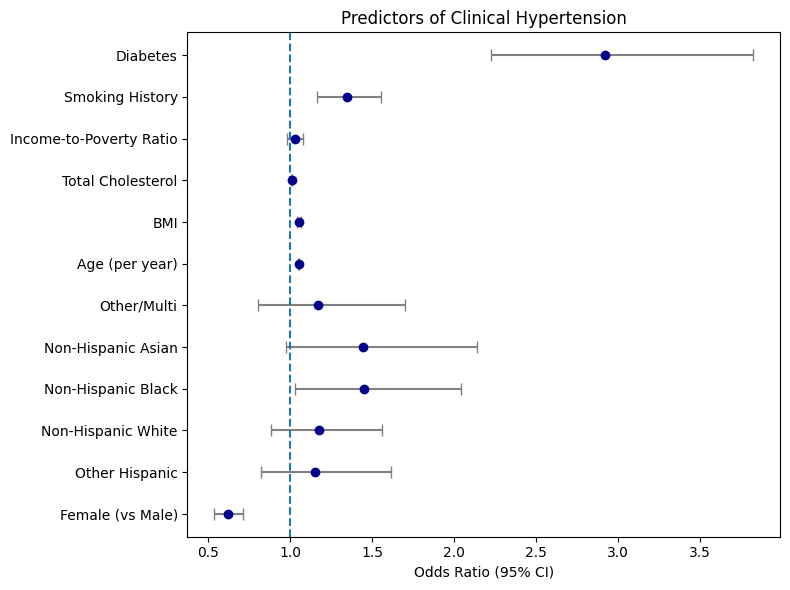

In [ ]:
# Create the forest plot for Clincal Hyptertension
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.errorbar(
    plot_df["OR"],
    plot_df["label"],
    xerr=[plot_df["OR"] - plot_df["Lower CI"],
          plot_df["Upper CI"] - plot_df["OR"]],
    fmt='o',
    color='darkblue',
    ecolor='gray',
    capsize=4
)

plt.axvline(x=1, linestyle='--')  # reference line for no effect

plt.xlabel("Odds Ratio (95% CI)")
plt.title("Predictors of Clinical Hypertension")

plt.tight_layout()
plt.show()

In [ ]:
# Race × Income interaction model for hypertension
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

# Copy data
df_htn_inter = df_htn_clean.copy()


# Convert categorical variables
df_htn_inter["RIAGENDR"] = df_htn_inter["RIAGENDR"].astype("category")
df_htn_inter["RIDRETH3"] = df_htn_inter["RIDRETH3"].astype("category")

# Logistic regression with interaction
formula_interaction = """
HTN_clinical ~ RIDAGEYR + BMXBMI + LBXTC + SMQ020 + diabetes +
C(RIAGENDR) + C(RIDRETH3) + INDFMPIR +
C(RIDRETH3):INDFMPIR
"""

# Fit model with robust SE
model_interaction = smf.logit(
    formula=formula_interaction,
    data=df_htn_inter
).fit(cov_type="HC3")

print(model_interaction.summary())

Optimization terminated successfully.
         Current function value: 0.541589
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:           HTN_clinical   No. Observations:                 4499
Model:                          Logit   Df Residuals:                     4481
Method:                           MLE   Df Model:                           17
Date:                Thu, 15 Oct 2026   Pseudo R-squ.:                  0.1823
Time:                        07:04:01   Log-Likelihood:                -2436.6
converged:                       True   LL-Null:                       -2979.9
Covariance Type:                  HC3   LLR p-value:                2.750e-220
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -5.4176      0.350    -15.467      0.000   

- **Age, BMI, total cholesterol, smoking history, and sex** remained significantly associated with hypertension (p < 0.05).
- The overall income effect for the **reference race group (Mexican American)** was not significant (p = 0.857).
- A significant **Non-Hispanic Black × Income interaction** was observed (β = 0.262, p = 0.016).
- This suggests that the **relationship between income and hypertension differed between Non-Hispanic Black and Mexican American participants**, after adjusting for the other predictors.
- The remaining **race × income interactions were not statistically significant** (p > 0.05).

## CVD Testing

In [ ]:
# CVD testing: inferential logistic regression

import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. Copy cleaned dataset
df_cvd_or = df_cvd_clean.copy()

# 2. Convert categorical variables
df_cvd_or["RIAGENDR"] = df_cvd_or["RIAGENDR"].astype("category")
df_cvd_or["RIDRETH3"] = df_cvd_or["RIDRETH3"].astype("category")

# 3. Logistic regression formula
# (IMPORTANT: includes HTN)
formula = """
CVD ~ RIDAGEYR + BMXBMI + LBXTC + INDFMPIR +
C(RIAGENDR) + C(RIDRETH3) + SMQ020 + diabetes +
HTN_clinical
"""

# 4. Fit model with robust SE
model_cvd = smf.logit(formula=formula, data=df_cvd_or).fit(cov_type="HC3")

print(model_cvd.summary())

# 5. Odds ratio table
params = model_cvd.params
conf = model_cvd.conf_int()
conf.columns = ["2.5%", "97.5%"]
pvals = model_cvd.pvalues

or_table = pd.DataFrame({
    "Coefficient": params,
    "OR": np.exp(params),
    "Lower CI": np.exp(conf["2.5%"]),
    "Upper CI": np.exp(conf["97.5%"]),
    "p-value": pvals
})

# Significance flag
or_table["Significant_0.05"] = or_table["p-value"] < 0.05

print("\n=== Odds Ratio Table for CVD Model ===")
print(or_table)

Optimization terminated successfully.
         Current function value: 0.263585
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                    CVD   No. Observations:                 4499
Model:                          Logit   Df Residuals:                     4485
Method:                           MLE   Df Model:                           13
Date:                Thu, 15 Oct 2026   Pseudo R-squ.:                  0.2485
Time:                        07:15:58   Log-Likelihood:                -1185.9
converged:                       True   LL-Null:                       -1577.9
Covariance Type:                  HC3   LLR p-value:                3.486e-159
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             -6.1559      0.602    -10.227      0.000      -7.336      -4.976
C(RIA

- **Age, BMI, total cholesterol, income, smoking history, sex, clinical hypertension, and Non-Hispanic Black race/ethnicity** were significantly associated with CVD (p < 0.05).
- Participants with **clinical hypertension had approximately 2.27 times the odds of CVD** compared with those without hypertension (OR = 2.271).
- Participants with a **smoking history had approximately 2.13 times the odds of CVD** compared with those without a smoking history (OR = 2.129).
- **Non-Hispanic Black participants had approximately 85% higher odds of CVD** compared with Mexican American participants (OR = 1.847).
- Each additional **year of age** was associated with approximately **7% higher odds of CVD** (OR = 1.070).
- **Females had approximately 32% lower odds of CVD** compared with males (OR = 0.676).
- Higher **income-to-poverty ratio and measured total cholesterol were inversely associated with prevalent CVD**.
- **Diabetes and the remaining race/ethnicity categories were not statistically significant** after adjustment.

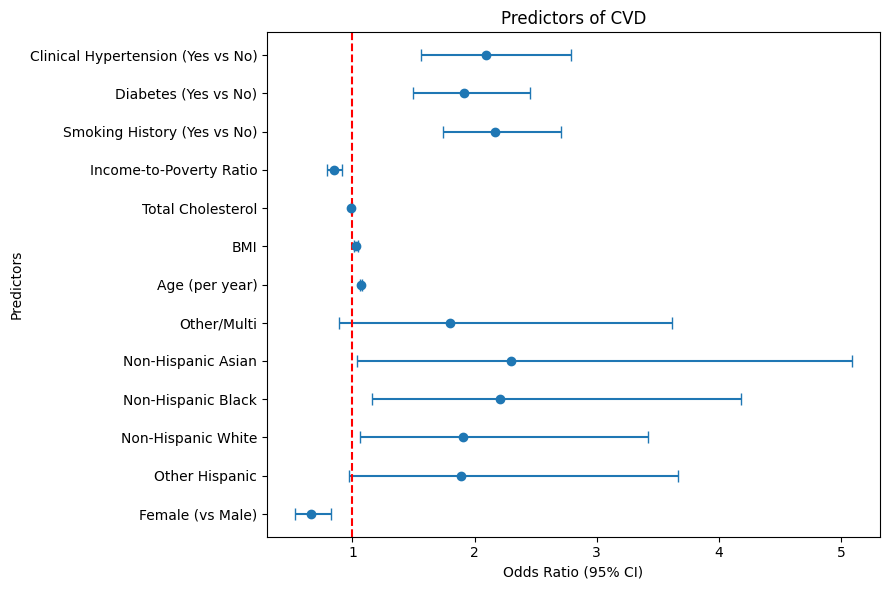

In [ ]:
# ============================================================
# FOREST PLOT FOR CVD LOGISTIC REGRESSION
# ============================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create CVD odds-ratio plotting table
# ------------------------------------------------------------

# Use the OR table created by the CVD logistic regression
or_cvd = or_table.copy()

# Remove intercept
or_cvd = or_cvd.drop(
    index="Intercept",
    errors="ignore"
)

# ------------------------------------------------------------
# 2. Create readable predictor labels
# ------------------------------------------------------------

label_map_cvd = {
    "RIDAGEYR": "Age (per year)",
    "BMXBMI": "BMI",
    "LBXTC": "Total Cholesterol",
    "INDFMPIR": "Income-to-Poverty Ratio",
    "SMQ020": "Smoking History (Yes vs No)",
    "diabetes": "Diabetes (Yes vs No)",
    "HTN_clinical": "Clinical Hypertension (Yes vs No)",
    "C(RIAGENDR)[T.1]": "Female (vs Male)",
    "C(RIDRETH3)[T.2.0]": "Other Hispanic",
    "C(RIDRETH3)[T.3.0]": "Non-Hispanic White",
    "C(RIDRETH3)[T.4.0]": "Non-Hispanic Black",
    "C(RIDRETH3)[T.6.0]": "Non-Hispanic Asian",
    "C(RIDRETH3)[T.7.0]": "Other/Multi"
}

or_cvd["label"] = or_cvd.index.map(
    lambda x: label_map_cvd.get(x, x)
)

# ------------------------------------------------------------
# 3. Forest plot
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.errorbar(
    x=or_cvd["OR"],
    y=or_cvd["label"],
    xerr=[
        or_cvd["OR"] - or_cvd["Lower CI"],
        or_cvd["Upper CI"] - or_cvd["OR"]
    ],
    fmt="o",
    capsize=4
)

# Reference line for no association
plt.axvline(
    x=1,
    linestyle="--",
    color="red"
)

plt.xlabel("Odds Ratio (95% CI)")
plt.ylabel("Predictors")
plt.title("Predictors of CVD")

plt.tight_layout()
plt.show()